### Solé-Boldó

In [73]:
import sys 
import os

# Data analysis & stats
import pandas as pd
import numpy as np
from scipy.stats import ranksums
from scipy.sparse import csr_matrix
from scipy.stats import ttest_ind


from sklearn.preprocessing import MinMaxScaler, RobustScaler

from scipy import sparse

# Single-cell
import scanpy as sc
import scanpy.external as sce
import anndata

# Plotting & palettes
import matplotlib.pyplot as plt
import seaborn as sns
from palettable.cartocolors.qualitative import Pastel_10, Safe_10, Bold_10, Vivid_10, Prism_10, Antique_5
from palettable.colorbrewer.qualitative import Set3_12

sys.path.append('../../')
from stacked_barplots import plot_stacked_bar

sys.path.append('/media/amon/2TB-HD/Olga/Aging_and_transcriptional_noise/tools')
import transcriptional_noise as tn

seed=10

In [74]:
adata = sc.read('../../data/raw_data/sole_boldo/SB2020_old_young.h5')

In [75]:
adata

AnnData object with n_obs × n_vars = 22291 × 39254
    obs: 'TotalUMIs', 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'leiden', 'fibro', 'melanocyte', 'peri', 'eritro', 'muscle', 'immune', 'endo', 'lymph', 'kerato', 'krt7/8/19', 'mt', 'neuro', 'T cells', 'B cells', 'APC', 'mast_cells', 'F', 'assigned_cats_std', 'assigned_cats_mean', 'assigned_cats_max', 'assigned_cats_CV', 'assigned_cats_fibro', 'assigned_cats_melanocyte', 'assigned_cats_peri', 'assigned_cats_eritro', 'assigned_cats_muscle', 'assigned_cats_immune', 'assigned_cats_endo', 'assigned_cats_lymph', 'assigned_cats_kerato', 'assigned_cats_krt7/8/19', 'assigned_cats_mt', 'assigned_cats_neuro', 'assigned_cats_T cells', 'assigned_cats_B cells', 'assigned_cats_APC', 'assigned_cats_mast_cells', 'assigned_cats_F', 'assigned_cats'
    var: 'Accession', 'AccessionVersion', 'Aliases', 'CcdsID', 'Chromosome', 'ChromosomeEnd', '

In [76]:
adata = sc.read_csv('../../data/raw_data/sole_boldo/Sole_boldo_counts.csv').transpose()

In [77]:
metadata = pd.read_csv('../../data/raw_data/sole_boldo/Sole_Boldo_metadata.csv', index_col=0, sep=';')

In [78]:
metadata

,orig.ident,nCount_RNA,nFeature_RNA,subj,percent.mito,age,integrated_snn_res.0.4,celltype.age
AAACCTGAGTTAAGTG-1,10X_PBMC,1971,852,S1,0.027905,YOUNG,6,6_YOUNG
AAACCTGTCCATTCTA-1,10X_PBMC,3148,978,S1,0.010165,YOUNG,6,6_YOUNG
AACACGTGTTCCACAA-1,10X_PBMC,4767,1466,S1,0.018670,YOUNG,6,6_YOUNG
AACCGCGCACGCGAAA-1,10X_PBMC,2487,879,S1,0.028951,YOUNG,6,6_YOUNG
AACCGCGCACTGAAGG-1,10X_PBMC,1983,838,S1,0.033787,YOUNG,6,6_YOUNG
...,...,...,...,...,...,...,...,...
TTGGAACTCAAGGCTT-5,10X_PBMC,3990,1367,S5,0.015539,OLD,15,15_OLD
TTTACTGTCGGTTAAC-5,10X_PBMC,1318,636,S5,0.021244,OLD,7,7_OLD
TTTGCGCTCTCGCTTG-5,10X_PBMC,1805,833,S5,0.019945,OLD,7,7_OLD
TTTGCGCTCTGCTTGC-5,10X_PBMC,2403,939,S5,0.016646,OLD,7,7_OLD


In [83]:
adata.obs['age'] = metadata.age 

In [86]:
adata.obs_names =  [nam.replace('.', '-') for nam in adata.obs_names]

In [87]:
adata.obs['individual']= metadata.subj

In [88]:
adata.X = csr_matrix(adata.X) # convert to sparse matrix

In [89]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [90]:
sc.pp.highly_variable_genes(adata)

In [91]:
sc.pp.pca(adata)

In [92]:
sce.pp.harmony_integrate(adata, key='individual')
sc.pp.neighbors(adata, use_rep='X_pca_harmony')
sc.tl.umap(adata)

2021-11-05 20:37:55,151 - harmonypy - INFO - Iteration 1 of 10
2021-11-05 20:38:06,669 - harmonypy - INFO - Iteration 2 of 10
2021-11-05 20:38:17,838 - harmonypy - INFO - Iteration 3 of 10
2021-11-05 20:38:29,135 - harmonypy - INFO - Converged after 3 iterations


In [93]:
metadata

,orig.ident,nCount_RNA,nFeature_RNA,subj,percent.mito,age,integrated_snn_res.0.4,celltype.age
AAACCTGAGTTAAGTG-1,10X_PBMC,1971,852,S1,0.027905,YOUNG,6,6_YOUNG
AAACCTGTCCATTCTA-1,10X_PBMC,3148,978,S1,0.010165,YOUNG,6,6_YOUNG
AACACGTGTTCCACAA-1,10X_PBMC,4767,1466,S1,0.018670,YOUNG,6,6_YOUNG
AACCGCGCACGCGAAA-1,10X_PBMC,2487,879,S1,0.028951,YOUNG,6,6_YOUNG
AACCGCGCACTGAAGG-1,10X_PBMC,1983,838,S1,0.033787,YOUNG,6,6_YOUNG
...,...,...,...,...,...,...,...,...
TTGGAACTCAAGGCTT-5,10X_PBMC,3990,1367,S5,0.015539,OLD,15,15_OLD
TTTACTGTCGGTTAAC-5,10X_PBMC,1318,636,S5,0.021244,OLD,7,7_OLD
TTTGCGCTCTCGCTTG-5,10X_PBMC,1805,833,S5,0.019945,OLD,7,7_OLD
TTTGCGCTCTGCTTGC-5,10X_PBMC,2403,939,S5,0.016646,OLD,7,7_OLD


# Select fibroblasts

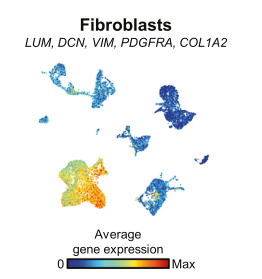

In [ ]:
sc.tl.leiden(adata, resolution=0.3)

In [ ]:
sc.pl.umap(adata, color=['leiden', 'LUM', 'DCN', 'VIM', 'PDGFRA', 'COL1A2'])

In [ ]:
adata_fibros = adata[adata.obs['leiden'].isin(['0', '6'])]

In [ ]:
sc.pp.filter_cells(adata_fibros, min_genes=100)
sc.pp.filter_genes(adata_fibros, min_cells=3)
sc.pp.highly_variable_genes(adata_fibros)

In [ ]:
sc.pp.pca(adata_fibros)

In [ ]:
sce.pp.harmony_integrate(adata_fibros, key='individual')
sc.pp.neighbors(adata_fibros, use_rep='X_pca_harmony')
sc.tl.umap(adata_fibros)

In [ ]:
sc.pl.umap(adata_fibros, color=['leiden', 'individual', 'LUM', 'DCN', 'VIM', 'PDGFRA', 'COL1A2'])

In [70]:
adata_fibros.obs['cell_type'] = 'Fibroblasts'

In [71]:
adata_fibros.write('../../data/anndatas/annotated/Sole_Boldo_fibros.h5ad')

/home/amon/anaconda3/lib/python3.7/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'cell_type' as categorical
